In [11]:
import numpy as np
import scipy as sp
import sympy as smp
import matplotlib.pyplot as plt
import random

import qiskit

import sys
sys.path.insert(0, '../../')

import oasis_dla

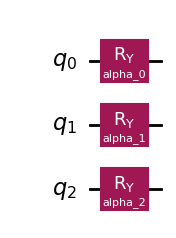

In [16]:
vqls_rz = oasis_dla.VQLS(qubits=3, ansatz_type=1)
vqls_ry = oasis_dla.VQLS(qubits=3, ansatz_type=0)

ansatz = qiskit.QuantumCircuit(3)
param = qiskit.circuit.Parameter('t0')
ansatz.cx(0, 1)
# ansatz.cx(1, 2)
# ansatz.ry(param, 2)
ansatz.ryy(param, 1, 2)
# ansatz.cx(1, 2)
ansatz.cx(0, 1)

vqls = oasis_dla.VQLS(qubits=3, optimizer="COBYQA")#, ansatz=ansatz)

display(vqls.ansatz.draw('mpl'))
# display(vqls_ry.ansatz.draw('mpl'))
# display(vqls_rz.ansatz.draw('mpl'))

In [17]:
A_0 = np.eye(8) # 2^3
A_1 = 0.2 * np.kron(np.kron(oasis_dla.X, oasis_dla.Z), np.eye(2))
A_2 = 0.2 * np.kron(np.kron(oasis_dla.X, np.eye(2)), np.eye(2))
A = A_0 + A_1 + A_2

data = vqls.generate_dataset(random_entries=[1+0j, 2+0j, 3+0j, 4+0j], shots=1)
display(smp.Matrix(data[0]))
print(data[0].shape)

# A = np.random.rand(8, 8)
# b = np.ones(8) / np.sqrt(8)

# print(A)
# vqls.solve(A, b)

Matrix([
[0.130098069178003,  0.193072929845001,  0.152845014045246,  0.226830689036126, 0.248436545625151,   0.36869395562505, 0.291874334072354,  0.433158102821685],
[  0.1685947715035, 0.0545198421794947,  0.198072656890472, 0.0640523421778687, 0.321950224991296,  0.104111623982443,  0.37824148330239,  0.122314979233838],
[0.148462242082075,   0.22032640631219, 0.0938254506389553,   0.13924230208294,  0.28350494985572,  0.420737460901988, 0.179169998415368,  0.265898462236581],
[0.192392999672257, 0.0622156659131822,  0.121588894528822, 0.0393191750928823,  0.36739555431556,  0.118807644270964, 0.232187342471558, 0.0750842814088267],
[0.244005565249954,  0.362118128877348,  0.286668620705812,  0.425432528276559, 0.195326017786184,  0.289874913342002, 0.229477717237168,  0.340557976617643],
[0.316208094238604,  0.102254745150324,  0.371495371995049,  0.120133435165054, 0.253124012872885, 0.0818547402781324, 0.297381379656068, 0.0961665996008225],
[0.278448508316812,  0.41323341423415

(8, 8)


In [18]:
# np.linalg.solve(A, b)
accuracies, t_times = vqls.accuracy_test(data)

Iteration: 0
Solving
Optimizing
 fun: 0.009964343475202475
   x: [ 1.949e-01  7.768e-01  8.533e-01]
 fun: 0.009964343475202475
   x: [ 1.949e-01  7.768e-01  8.533e-01]
 fun: 0.009964343475202475
   x: [ 1.949e-01  7.768e-01  8.533e-01]
 fun: 0.0027222974613692608
   x: [ 1.949e-01  7.768e-01  1.853e+00]
 fun: 0.0027222974613692608
   x: [ 1.949e-01  7.768e-01  1.853e+00]
 fun: 0.0027222974613692608
   x: [ 1.949e-01  7.768e-01  1.853e+00]
 fun: 0.0027222974613692608
   x: [ 1.949e-01  7.768e-01  1.853e+00]
 fun: 0.001462364388722881
   x: [ 6.553e-01  8.101e-01  1.710e+00]
 fun: 0.001462364388722881
   x: [ 6.553e-01  8.101e-01  1.710e+00]
 fun: 0.0011255787038438325
   x: [ 7.365e-01  6.398e-01  1.861e+00]
 fun: 0.0002208019123438043
   x: [ 5.998e-01  6.243e-01  2.060e+00]
 fun: 6.168805203149441e-05
   x: [ 5.397e-01  7.561e-01  2.253e+00]
 fun: 6.168805203149441e-05
   x: [ 5.397e-01  7.561e-01  2.253e+00]
 fun: 6.168805203149441e-05
   x: [ 5.397e-01  7.561e-01  2.253e+00]
 fun: 9

Average Accuracy = 0.9999987043452789


<Axes: xlabel='Test Number', ylabel='Accuracy'>

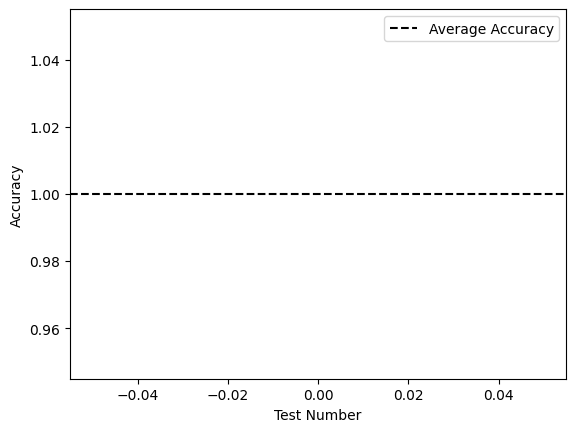

In [19]:
vqls.plot_tests(accuracies)

In [ ]:
1/60 * t_times

TypeError: unsupported operand type(s) for /: 'list' and 'int'